# Analiza szeregu czasowego - Grypa w Polsce (2010-2023)

Analiza danych historycznych zachorowań na grypę w Polsce.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings('ignore')

# Ustawienia wizualizacji
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (15, 8)
plt.rcParams['font.size'] = 10

## 1. Wczytanie i przygotowanie danych

In [20]:
# Wczytanie danych
df = pd.read_excel('grypa_polska_2007_2023_CLEANED.xlsx')

print("Podstawowe informacje o danych:")
print(f"Zakres lat: {df['Rok'].min()} - {df['Rok'].max()}")
print(f"Liczba obserwacji: {len(df)}")
print(f"\nPierwsze wiersze:")
df.head(10)

Podstawowe informacje o danych:
Zakres lat: 2010 - 2023
Liczba obserwacji: 647

Pierwsze wiersze:


,Choroba,Rok,Numer tygodnia,Liczba przypadków na 100 tys.
0,Grypa,2010,53,6.22
1,Grypa,2010,1,5.22
2,Grypa,2010,2,6.22
3,Grypa,2010,4,4.46
4,Grypa,2010,5,5.92
5,Grypa,2010,6,5.25
6,Grypa,2010,7,5.00
7,Grypa,2010,8,5.39
8,Grypa,2010,9,4.77
9,Grypa,2010,10,5.57


In [21]:
# Utworzenie indeksu czasowego
# Konwersja rok + tydzień ISO na datę (poniedziałek danego tygodnia)
# Obsługa problematycznych tygodni 53, które nie istnieją w niektórych latach ISO

def safe_iso_to_date(year, week):
    """Bezpieczna konwersja rok+tydzień ISO na datę z obsługą tygodnia 53"""
    try:
        return pd.to_datetime(f"{int(year)}-W{int(week)}-1", format='%G-W%V-%u')
    except ValueError:
        # Jeśli tydzień 53 nie istnieje w danym roku ISO, użyj tygodnia 1 następnego roku
        if week == 53:
            return pd.to_datetime(f"{int(year)+1}-W01-1", format='%G-W%V-%u')
        raise

df['date'] = df.apply(lambda row: safe_iso_to_date(row['Rok'], row['Numer tygodnia']), axis=1)
df = df.sort_values('date').reset_index(drop=True)

# Utworzenie szeregu czasowego
ts = df.set_index('date')['Liczba przypadków na 100 tys.']

print(f"Szereg czasowy obejmuje okres: {ts.index.min().date()} - {ts.index.max().date()}")
print(f"Liczba tygodni: {len(ts)}")
print(f"\nStatystyki opisowe:")
print(ts.describe())

Szereg czasowy obejmuje okres: 2010-01-04 - 2023-12-25
Liczba tygodni: 647

Statystyki opisowe:
count    647.000000
mean      25.172612
std       21.105185
min        0.680000
25%        9.585000
50%       19.750000
75%       34.910000
max      115.800000
Name: Liczba przypadków na 100 tys., dtype: float64


## 2. Wizualizacja szeregu czasowego

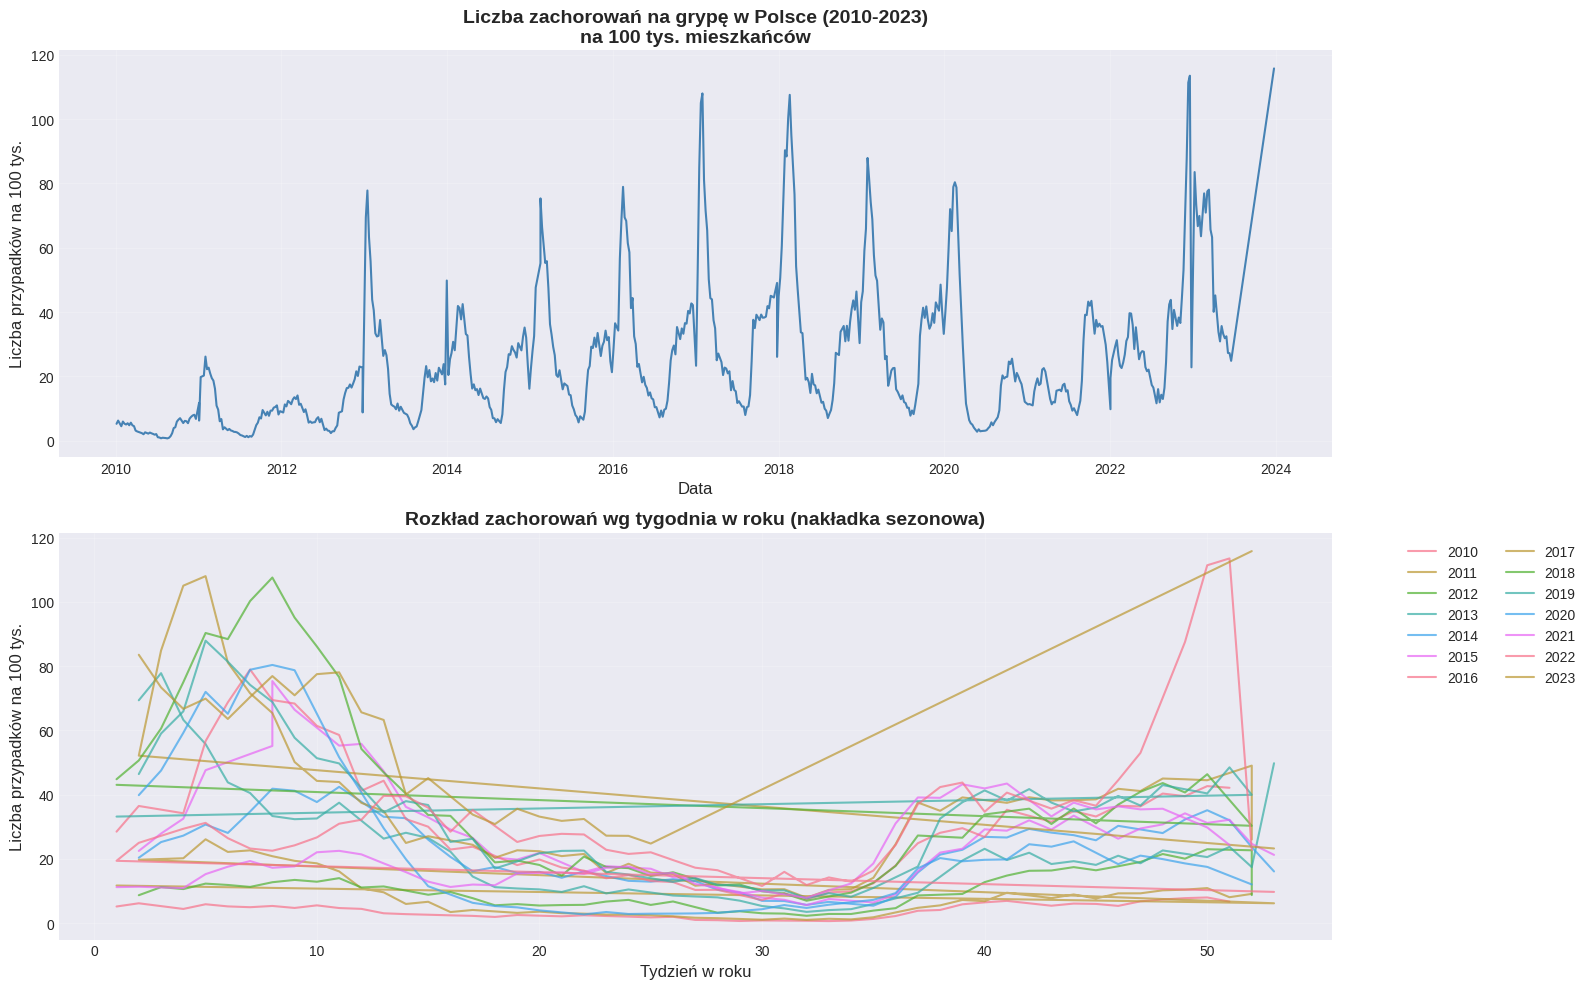

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Pełny szereg
axes[0].plot(ts.index, ts.values, linewidth=1.5, color='steelblue')
axes[0].set_title('Liczba zachorowań na grypę w Polsce (2010-2023)\nna 100 tys. mieszkańców', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Data', fontsize=12)
axes[0].set_ylabel('Liczba przypadków na 100 tys.', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Rozkład rocznie z wyróżnieniem sezonów
yearly_data = df.copy()
yearly_data['year'] = yearly_data['date'].dt.year
yearly_data['week'] = yearly_data['Numer tygodnia']

for year in sorted(yearly_data['year'].unique()):
    year_data = yearly_data[yearly_data['year'] == year]
    axes[1].plot(year_data['week'], year_data['Liczba przypadków na 100 tys.'], 
                 label=str(year), alpha=0.7, linewidth=1.5)

axes[1].set_title('Rozkład zachorowań wg tygodnia w roku (nakładka sezonowa)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Tydzień w roku', fontsize=12)
axes[1].set_ylabel('Liczba przypadków na 100 tys.', fontsize=12)
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Dekompozycja szeregu czasowego

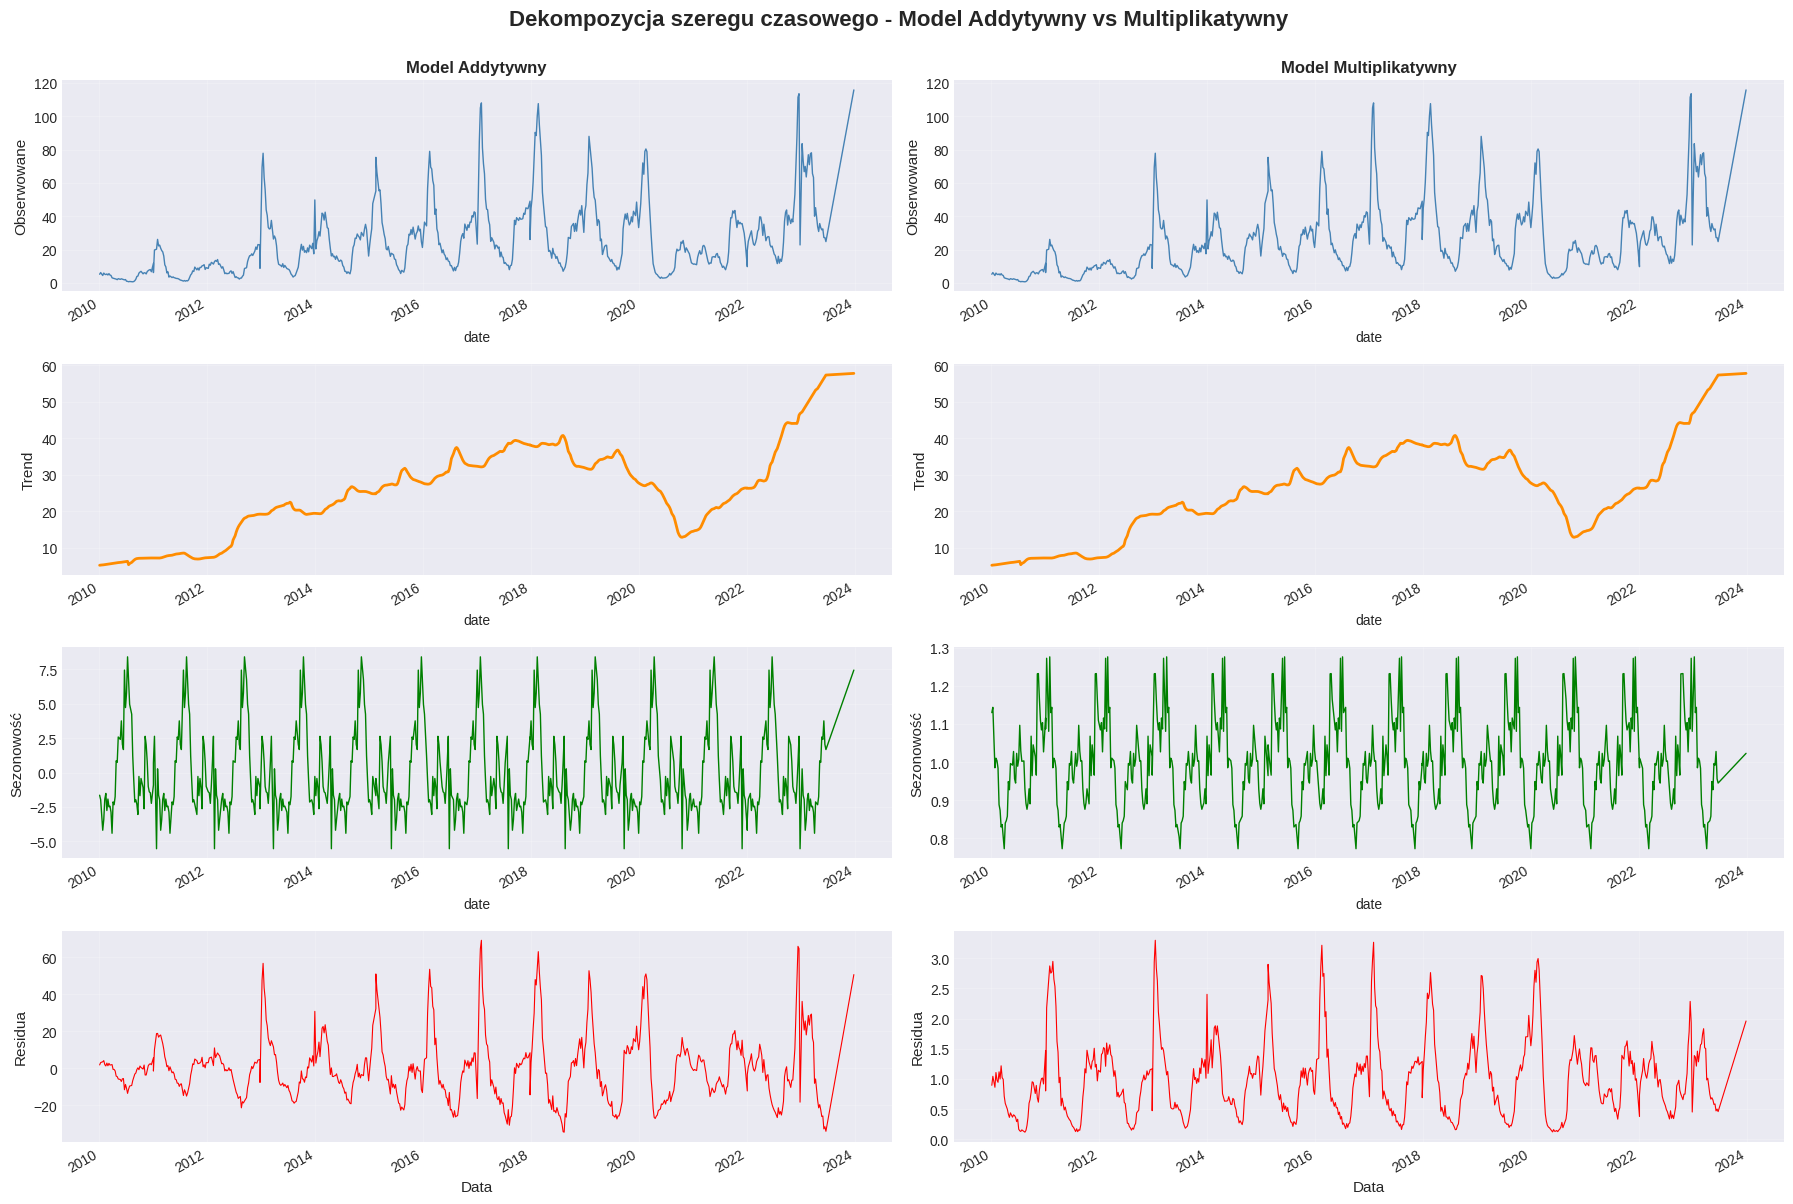

In [23]:
# Dekompozycja addytywna (sezon + trend + szum)
# Okres sezonowości: ~52 tygodnie (rok)
decomposition_add = seasonal_decompose(ts, model='additive', period=52, extrapolate_trend='freq')

# Dekompozycja multiplikatywna
decomposition_mult = seasonal_decompose(ts, model='multiplicative', period=52, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 2, figsize=(18, 12))
fig.suptitle('Dekompozycja szeregu czasowego - Model Addytywny vs Multiplikatywny', fontsize=16, fontweight='bold', y=1.00)

# Model addytywny
decomposition_add.observed.plot(ax=axes[0, 0], color='steelblue', linewidth=1)
axes[0, 0].set_ylabel('Obserwowane', fontsize=11)
axes[0, 0].set_title('Model Addytywny', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

decomposition_add.trend.plot(ax=axes[1, 0], color='darkorange', linewidth=2)
axes[1, 0].set_ylabel('Trend', fontsize=11)
axes[1, 0].grid(True, alpha=0.3)

decomposition_add.seasonal.plot(ax=axes[2, 0], color='green', linewidth=1)
axes[2, 0].set_ylabel('Sezonowość', fontsize=11)
axes[2, 0].grid(True, alpha=0.3)

decomposition_add.resid.plot(ax=axes[3, 0], color='red', linewidth=0.8)
axes[3, 0].set_ylabel('Residua', fontsize=11)
axes[3, 0].set_xlabel('Data', fontsize=11)
axes[3, 0].grid(True, alpha=0.3)

# Model multiplikatywny
decomposition_mult.observed.plot(ax=axes[0, 1], color='steelblue', linewidth=1)
axes[0, 1].set_ylabel('Obserwowane', fontsize=11)
axes[0, 1].set_title('Model Multiplikatywny', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

decomposition_mult.trend.plot(ax=axes[1, 1], color='darkorange', linewidth=2)
axes[1, 1].set_ylabel('Trend', fontsize=11)
axes[1, 1].grid(True, alpha=0.3)

decomposition_mult.seasonal.plot(ax=axes[2, 1], color='green', linewidth=1)
axes[2, 1].set_ylabel('Sezonowość', fontsize=11)
axes[2, 1].grid(True, alpha=0.3)

decomposition_mult.resid.plot(ax=axes[3, 1], color='red', linewidth=0.8)
axes[3, 1].set_ylabel('Residua', fontsize=11)
axes[3, 1].set_xlabel('Data', fontsize=11)
axes[3, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Wizualizacja komponentu sezonowego

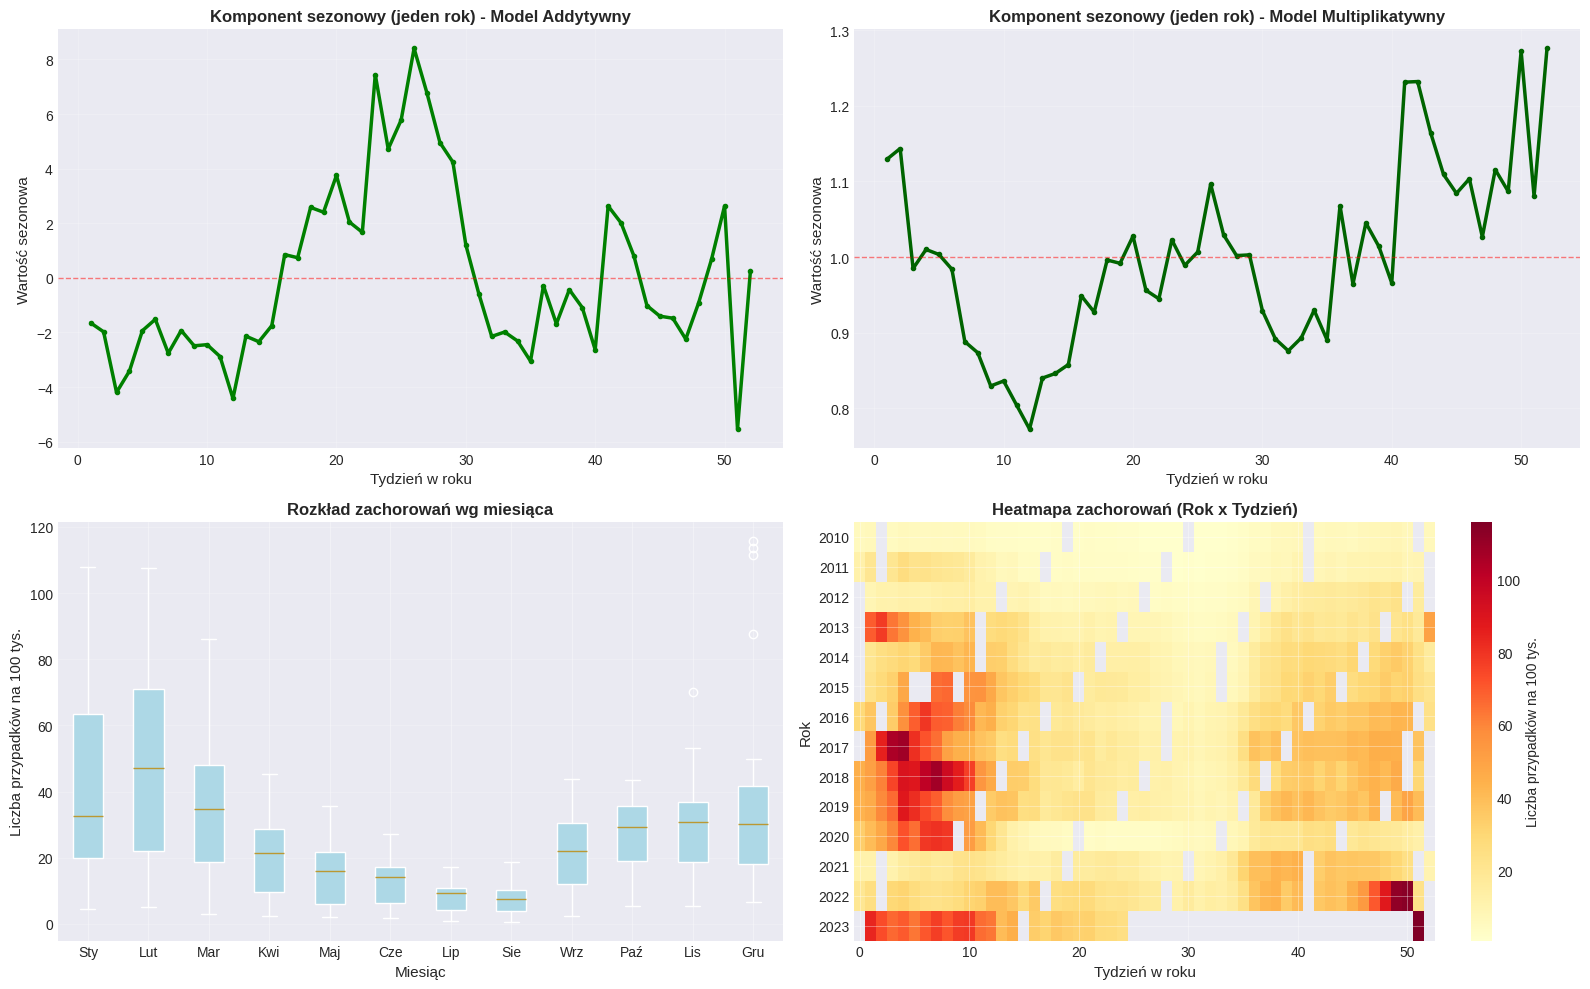

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Komponent sezonowy - model addytywny (jeden rok)
seasonal_pattern = decomposition_add.seasonal[:52]
axes[0, 0].plot(range(1, 53), seasonal_pattern.values, linewidth=2.5, color='green', marker='o', markersize=3)
axes[0, 0].set_title('Komponent sezonowy (jeden rok) - Model Addytywny', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Tydzień w roku', fontsize=11)
axes[0, 0].set_ylabel('Wartość sezonowa', fontsize=11)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)

# Komponent sezonowy - model multiplikatywny
seasonal_pattern_mult = decomposition_mult.seasonal[:52]
axes[0, 1].plot(range(1, 53), seasonal_pattern_mult.values, linewidth=2.5, color='darkgreen', marker='o', markersize=3)
axes[0, 1].set_title('Komponent sezonowy (jeden rok) - Model Multiplikatywny', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Tydzień w roku', fontsize=11)
axes[0, 1].set_ylabel('Wartość sezonowa', fontsize=11)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].axhline(y=1, color='red', linestyle='--', linewidth=1, alpha=0.5)

# Boxplot sezonowości wg miesiąca
df_with_month = df.copy()
df_with_month['month'] = df_with_month['date'].dt.month
month_names = ['Sty', 'Lut', 'Mar', 'Kwi', 'Maj', 'Cze', 'Lip', 'Sie', 'Wrz', 'Paź', 'Lis', 'Gru']

boxplot_data = [df_with_month[df_with_month['month'] == m]['Liczba przypadków na 100 tys.'].values for m in range(1, 13)]
bp = axes[1, 0].boxplot(boxplot_data, labels=month_names, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
axes[1, 0].set_title('Rozkład zachorowań wg miesiąca', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Miesiąc', fontsize=11)
axes[1, 0].set_ylabel('Liczba przypadków na 100 tys.', fontsize=11)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Heatmapa sezonowości (rok x tydzień)
pivot_data = df.pivot_table(values='Liczba przypadków na 100 tys.', 
                             index='Rok', 
                             columns='Numer tygodnia', 
                             aggfunc='mean')
im = axes[1, 1].imshow(pivot_data.values, aspect='auto', cmap='YlOrRd', interpolation='nearest')
axes[1, 1].set_title('Heatmapa zachorowań (Rok x Tydzień)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Tydzień w roku', fontsize=11)
axes[1, 1].set_ylabel('Rok', fontsize=11)
axes[1, 1].set_yticks(range(len(pivot_data.index)))
axes[1, 1].set_yticklabels(pivot_data.index)
plt.colorbar(im, ax=axes[1, 1], label='Liczba przypadków na 100 tys.')

plt.tight_layout()
plt.show()

## 5. Funkcje autokorelacji (ACF i PACF)

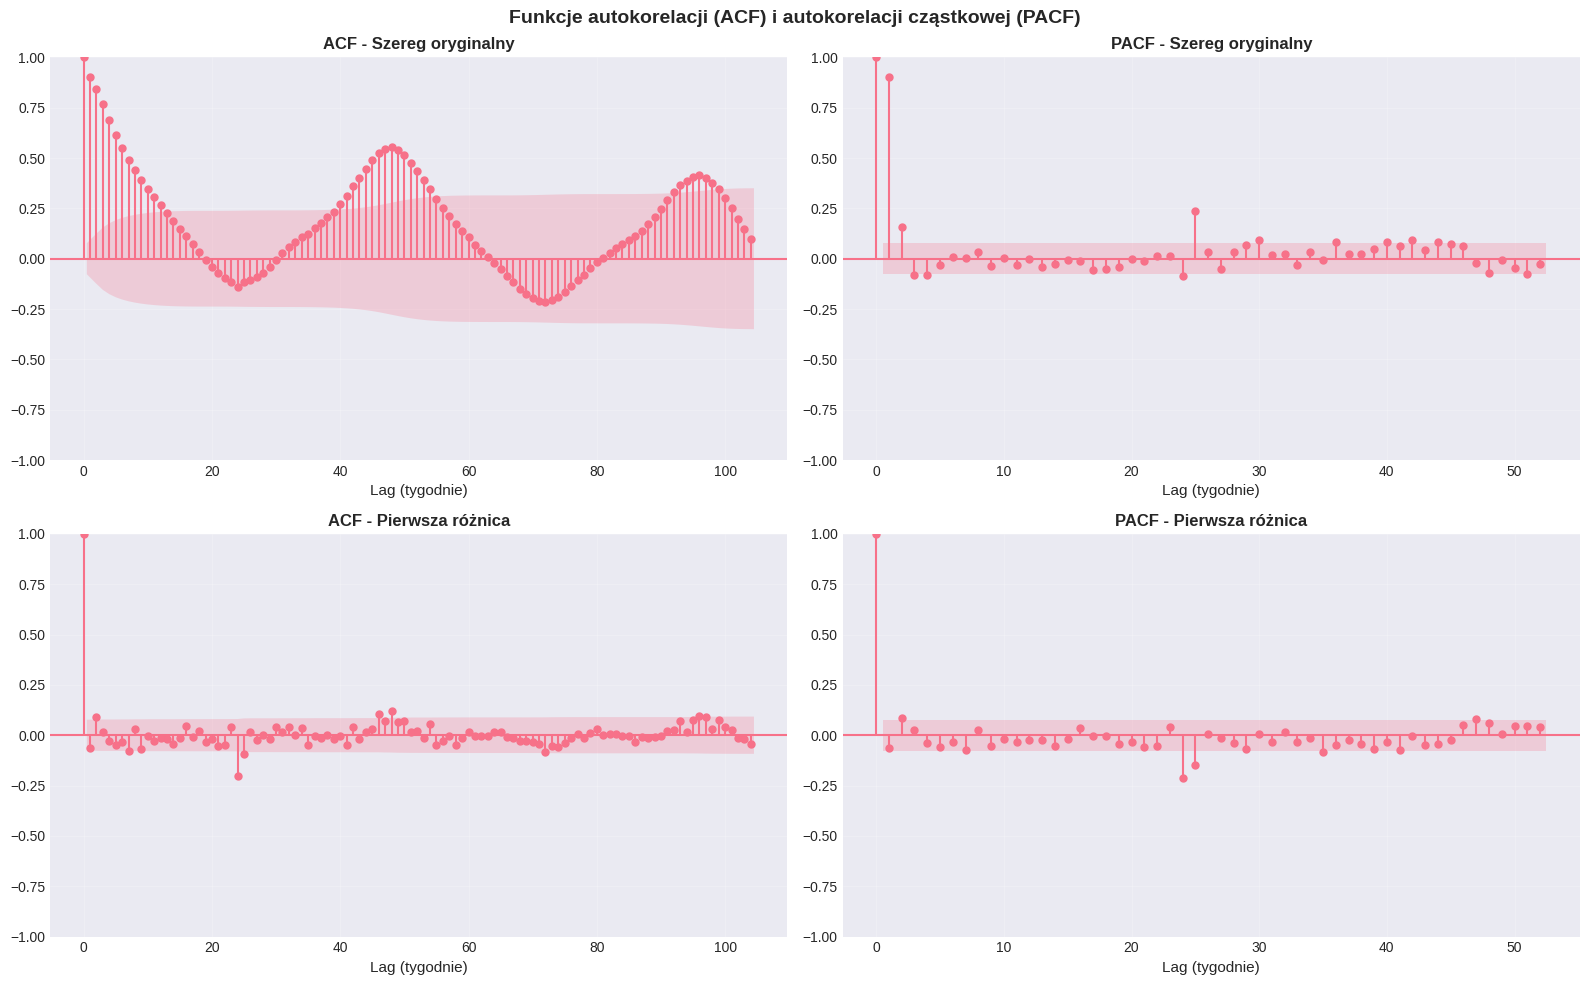

Interpretacja:
- ACF (Autocorrelation Function): pokazuje korelację między szeregiem a jego opóźnieniami
- PACF (Partial Autocorrelation Function): pokazuje korelację po usunięciu wpływu pośrednich opóźnień
- Widoczna silna sezonowość roczna (lag ~52 tygodnie)


In [35]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Funkcje autokorelacji (ACF) i autokorelacji cząstkowej (PACF)', fontsize=14, fontweight='bold')

# ACF dla szeregu oryginalnego
plot_acf(ts.dropna(), lags=104, ax=axes[0, 0], alpha=0.05)
axes[0, 0].set_title('ACF - Szereg oryginalny', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Lag (tygodnie)', fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# PACF dla szeregu oryginalnego
plot_pacf(ts.dropna(), lags=52, ax=axes[0, 1], alpha=0.05, method='ywm')
axes[0, 1].set_title('PACF - Szereg oryginalny', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Lag (tygodnie)', fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# Pierwsza różnica
ts_diff = ts.diff().dropna()

# ACF dla pierwszej różnicy
plot_acf(ts_diff, lags=104, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title('ACF - Pierwsza różnica', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Lag (tygodnie)', fontsize=11)
axes[1, 0].grid(True, alpha=0.3)

# PACF dla pierwszej różnicy
plot_pacf(ts_diff, lags=52, ax=axes[1, 1], alpha=0.05, method='ywm')
axes[1, 1].set_title('PACF - Pierwsza różnica', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Lag (tygodnie)', fontsize=11)
axes[1, 1].grid(True, alpha=0.3)



plt.tight_layout()
plt.show()

print("Interpretacja:")
print("- ACF (Autocorrelation Function): pokazuje korelację między szeregiem a jego opóźnieniami")
print("- PACF (Partial Autocorrelation Function): pokazuje korelację po usunięciu wpływu pośrednich opóźnień")
print("- Widoczna silna sezonowość roczna (lag ~52 tygodnie)")

## 6. Testy stacjonarności

In [34]:
def test_stationarity(timeseries, title='Szereg czasowy'):
    """
    Przeprowadza testy stacjonarności i wizualizuje wyniki
    """
    print(f"\n{'='*60}")
    print(f"Test stacjonarności dla: {title}")
    print(f"{'='*60}\n")
    
    # Test Augmented Dickey-Fuller (ADF)
    print("1. Test ADF (Augmented Dickey-Fuller):")
    print("   H0: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)")
    print("   H1: Szereg jest stacjonarny")
    
    adf_result = adfuller(timeseries.dropna(), autolag='AIC')
    print(f"\n   Statystyka testowa: {adf_result[0]:.6f}")
    print(f"   p-wartość: {adf_result[1]:.6f}")
    print(f"   Liczba opóźnień użytych: {adf_result[2]}")
    print(f"   Liczba obserwacji: {adf_result[3]}")
    print(f"\n   Wartości krytyczne:")
    for key, value in adf_result[4].items():
        print(f"      {key}: {value:.3f}")
    
    if adf_result[1] < 0.05:
        print(f"\n   ✓ WNIOSEK: Szereg JEST stacjonarny (p < 0.05)")
    else:
        print(f"\n   ✗ WNIOSEK: Szereg NIE JEST stacjonarny (p >= 0.05)")
    
    # Test KPSS
    print("\n" + "="*60)
    print("2. Test KPSS (Kwiatkowski-Phillips-Schmidt-Shin):")
    print("   H0: Szereg JEST stacjonarny")
    print("   H1: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)")
    
    kpss_result = kpss(timeseries.dropna(), regression='ct', nlags='auto')
    print(f"\n   Statystyka testowa: {kpss_result[0]:.6f}")
    print(f"   p-wartość: {kpss_result[1]:.6f}")
    print(f"   Liczba opóźnień użytych: {kpss_result[2]}")
    print(f"\n   Wartości krytyczne:")
    for key, value in kpss_result[3].items():
        print(f"      {key}: {value:.3f}")
    
    if kpss_result[1] > 0.05:
        print(f"\n   ✓ WNIOSEK: Szereg JEST stacjonarny (p > 0.05)")
    else:
        print(f"\n   ✗ WNIOSEK: Szereg NIE JEST stacjonarny (p <= 0.05)")
    
    print("\n" + "="*60)
    
    return adf_result, kpss_result

# Test dla szeregu oryginalnego
adf_orig, kpss_orig = test_stationarity(ts, 'Szereg oryginalny')


Test stacjonarności dla: Szereg oryginalny

1. Test ADF (Augmented Dickey-Fuller):
   H0: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)
   H1: Szereg jest stacjonarny

   Statystyka testowa: -5.016584
   p-wartość: 0.000021
   Liczba opóźnień użytych: 3
   Liczba obserwacji: 643

   Wartości krytyczne:
      1%: -3.441
      5%: -2.866
      10%: -2.569

   ✓ WNIOSEK: Szereg JEST stacjonarny (p < 0.05)

2. Test KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
   H0: Szereg JEST stacjonarny
   H1: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)

   Statystyka testowa: 0.169330
   p-wartość: 0.030558
   Liczba opóźnień użytych: 15

   Wartości krytyczne:
      10%: 0.119
      5%: 0.146
      2.5%: 0.176
      1%: 0.216

   ✗ WNIOSEK: Szereg NIE JEST stacjonarny (p <= 0.05)



In [27]:
# Test dla pierwszej różnicy
ts_diff = ts.diff().dropna()
adf_diff, kpss_diff = test_stationarity(ts_diff, 'Pierwsza różnica')


Test stacjonarności dla: Pierwsza różnica

1. Test ADF (Augmented Dickey-Fuller):
   H0: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)
   H1: Szereg jest stacjonarny

   Statystyka testowa: -15.325585
   p-wartość: 0.000000
   Liczba opóźnień użytych: 1
   Liczba obserwacji: 644

   Wartości krytyczne:
      1%: -3.441
      5%: -2.866
      10%: -2.569

   ✓ WNIOSEK: Szereg JEST stacjonarny (p < 0.05)

2. Test KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
   H0: Szereg JEST stacjonarny
   H1: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)

   Statystyka testowa: 0.028278
   p-wartość: 0.100000
   Liczba opóźnień użytych: 1

   Wartości krytyczne:
      10%: 0.119
      5%: 0.146
      2.5%: 0.176
      1%: 0.216

   ✓ WNIOSEK: Szereg JEST stacjonarny (p > 0.05)



In [28]:
# Test dla różnicy sezonowej (lag=52)
ts_seasonal_diff = ts.diff(52).dropna()
adf_sdiff, kpss_sdiff = test_stationarity(ts_seasonal_diff, 'Różnica sezonowa (lag=52)')


Test stacjonarności dla: Różnica sezonowa (lag=52)

1. Test ADF (Augmented Dickey-Fuller):
   H0: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)
   H1: Szereg jest stacjonarny

   Statystyka testowa: -7.323049
   p-wartość: 0.000000
   Liczba opóźnień użytych: 3
   Liczba obserwacji: 591

   Wartości krytyczne:
      1%: -3.441
      5%: -2.866
      10%: -2.569

   ✓ WNIOSEK: Szereg JEST stacjonarny (p < 0.05)

2. Test KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
   H0: Szereg JEST stacjonarny
   H1: Szereg ma pierwiastek jednostkowy (NIE jest stacjonarny)

   Statystyka testowa: 0.161475
   p-wartość: 0.037104
   Liczba opóźnień użytych: 14

   Wartości krytyczne:
      10%: 0.119
      5%: 0.146
      2.5%: 0.176
      1%: 0.216

   ✗ WNIOSEK: Szereg NIE JEST stacjonarny (p <= 0.05)



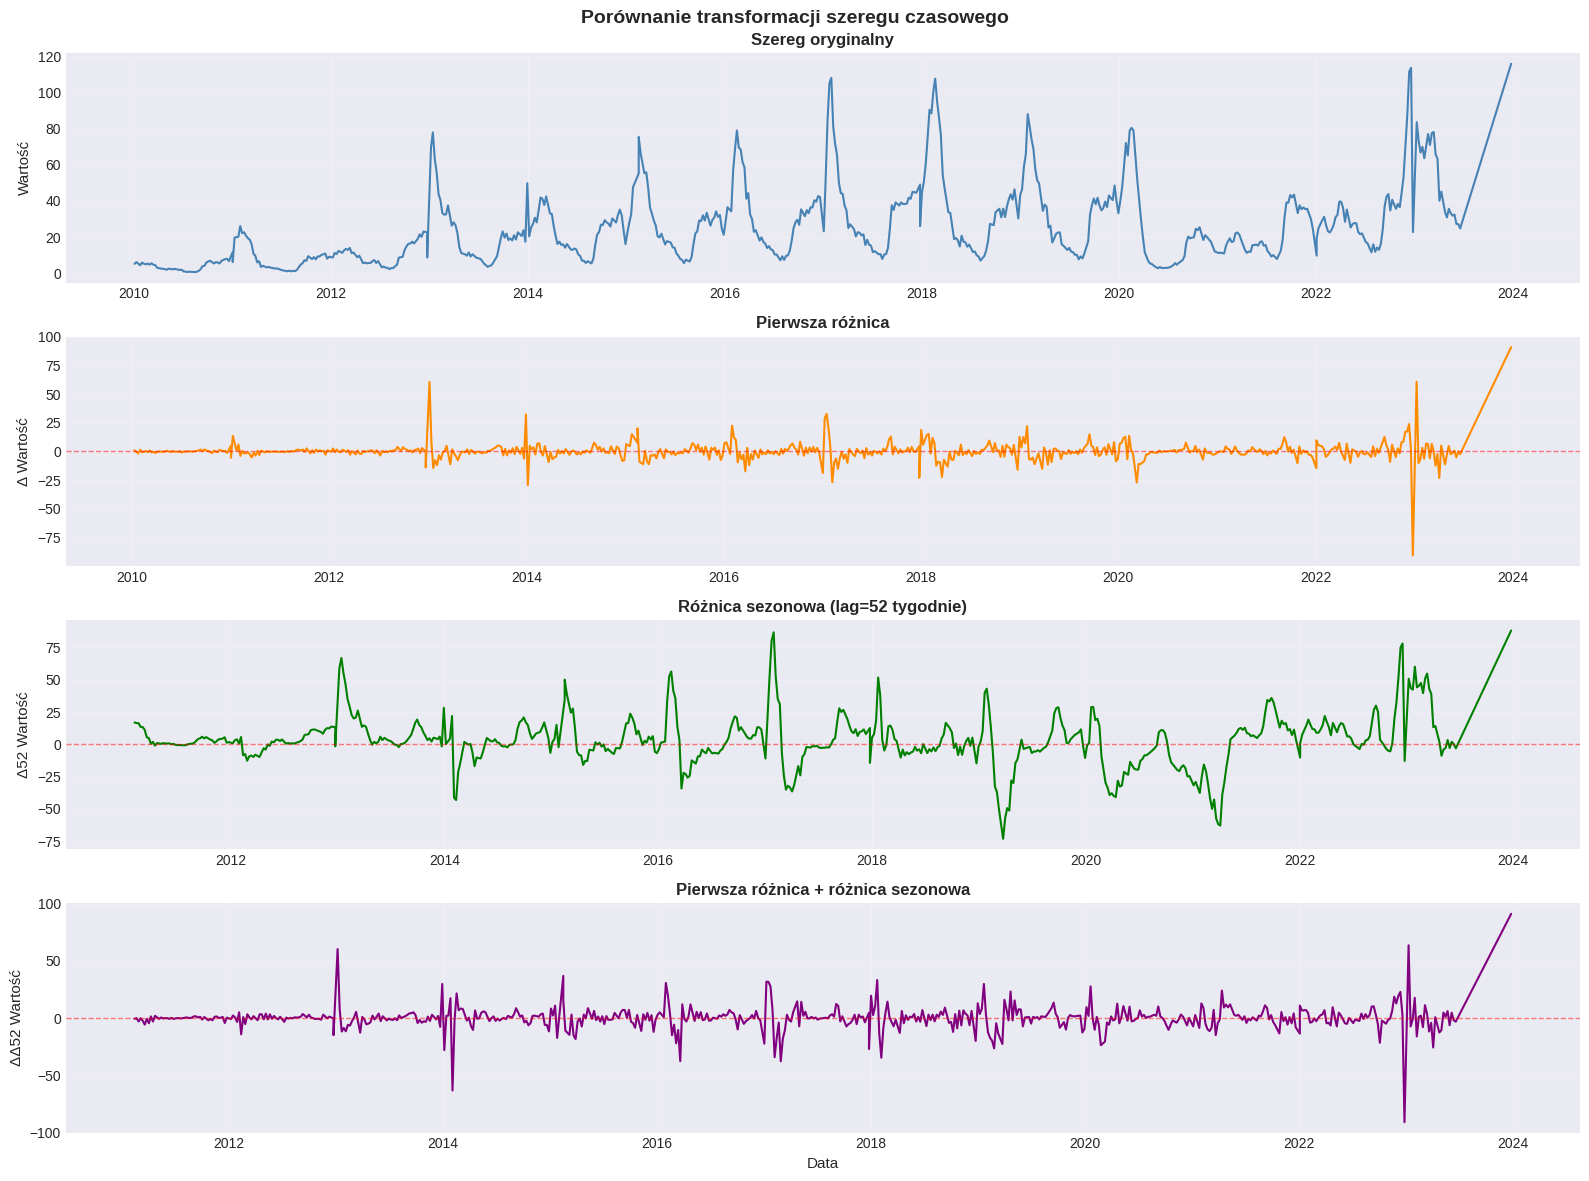

In [29]:
# Wizualizacja porównawcza transformacji
fig, axes = plt.subplots(4, 1, figsize=(16, 12))
fig.suptitle('Porównanie transformacji szeregu czasowego', fontsize=14, fontweight='bold')

# Oryginalny
axes[0].plot(ts.index, ts.values, linewidth=1.5, color='steelblue')
axes[0].set_title('Szereg oryginalny', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Wartość', fontsize=11)
axes[0].grid(True, alpha=0.3)

# Pierwsza różnica
axes[1].plot(ts_diff.index, ts_diff.values, linewidth=1.5, color='darkorange')
axes[1].set_title('Pierwsza różnica', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Δ Wartość', fontsize=11)
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
axes[1].grid(True, alpha=0.3)

# Różnica sezonowa
axes[2].plot(ts_seasonal_diff.index, ts_seasonal_diff.values, linewidth=1.5, color='green')
axes[2].set_title('Różnica sezonowa (lag=52 tygodnie)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Δ52 Wartość', fontsize=11)
axes[2].axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
axes[2].grid(True, alpha=0.3)

# Pierwsza różnica + różnica sezonowa
ts_double_diff = ts.diff().diff(52).dropna()
axes[3].plot(ts_double_diff.index, ts_double_diff.values, linewidth=1.5, color='purple')
axes[3].set_title('Pierwsza różnica + różnica sezonowa', fontsize=12, fontweight='bold')
axes[3].set_ylabel('ΔΔ52 Wartość', fontsize=11)
axes[3].set_xlabel('Data', fontsize=11)
axes[3].axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Podsumowanie wyników analizy

In [30]:
print("\n" + "="*80)
print("PODSUMOWANIE ANALIZY SZEREGU CZASOWEGO - GRYPA W POLSCE")
print("="*80)

print("\n1. CHARAKTERYSTYKA DANYCH:")
print(f"   - Okres: {ts.index.min().date()} do {ts.index.max().date()}")
print(f"   - Liczba obserwacji: {len(ts)} tygodni")
print(f"   - Średnia zachorowań: {ts.mean():.2f} na 100 tys.")
print(f"   - Odchylenie standardowe: {ts.std():.2f}")
print(f"   - Minimum: {ts.min():.2f}")
print(f"   - Maximum: {ts.max():.2f}")

print("\n2. SEZONOWOŚĆ:")
print("   - Wyraźna sezonowość roczna (okres ~52 tygodnie)")
print("   - Szczyt zachorowań: koniec zimy/wiosna (styczeń-marzec)")
print("   - Minimum zachorowań: lato (czerwiec-sierpień)")

print("\n3. TREND:")
trend_values = decomposition_add.trend.dropna()
trend_change = trend_values.iloc[-1] - trend_values.iloc[0]
print(f"   - Zmiana trendu w okresie: {trend_change:.2f}")
if abs(trend_change) < 5:
    print("   - Trend względnie stabilny")
elif trend_change > 0:
    print("   - Trend rosnący")
else:
    print("   - Trend malejący")

print("\n4. STACJONARNOŚĆ:")
print(f"   - Szereg oryginalny: {'STACJONARNY' if adf_orig[1] < 0.05 else 'NIESTACJONARNY'}")
print(f"   - Pierwsza różnica: {'STACJONARNY' if adf_diff[1] < 0.05 else 'NIESTACJONARNY'}")
print(f"   - Różnica sezonowa: {'STACJONARNY' if adf_sdiff[1] < 0.05 else 'NIESTACJONARNY'}")

print("\n5. REKOMENDACJE DLA MODELU:")
print("   - Model powinien uwzględniać silną sezonowość roczną")
print("   - Sugerowane modele: SARIMA, Prophet, modele z komponentami sezonowymi")
print("   - Rozważyć użycie różnicowania sezonowego")
print("   - Warto uwzględnić zmienne egzogeniczne (pogoda, szczepienia)")

print("\n" + "="*80)



PODSUMOWANIE ANALIZY SZEREGU CZASOWEGO - GRYPA W POLSCE

1. CHARAKTERYSTYKA DANYCH:
   - Okres: 2010-01-04 do 2023-12-25
   - Liczba obserwacji: 647 tygodni
   - Średnia zachorowań: 25.17 na 100 tys.
   - Odchylenie standardowe: 21.11
   - Minimum: 0.68
   - Maximum: 115.80

2. SEZONOWOŚĆ:
   - Wyraźna sezonowość roczna (okres ~52 tygodnie)
   - Szczyt zachorowań: koniec zimy/wiosna (styczeń-marzec)
   - Minimum zachorowań: lato (czerwiec-sierpień)

3. TREND:
   - Zmiana trendu w okresie: 52.62
   - Trend rosnący

4. STACJONARNOŚĆ:
   - Szereg oryginalny: STACJONARNY
   - Pierwsza różnica: STACJONARNY
   - Różnica sezonowa: STACJONARNY

5. REKOMENDACJE DLA MODELU:
   - Model powinien uwzględniać silną sezonowość roczną
   - Sugerowane modele: SARIMA, Prophet, modele z komponentami sezonowymi
   - Rozważyć użycie różnicowania sezonowego
   - Warto uwzględnić zmienne egzogeniczne (pogoda, szczepienia)



In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (15, 8)
# Szereg czasowy
ts = df.set_index('date')['Liczba przypadków na 100 tys.']

# Podział train/test (ostatnie 26 tygodni = pół roku)
train_size = len(ts) - 26
train = ts.iloc[:train_size]
test = ts.iloc[train_size:]

print(f"Train: {len(train)} tygodni ({train.index.min().date()} - {train.index.max().date()})")
print(f"Test:  {len(test)} tygodni ({test.index.min().date()} - {test.index.max().date()})")
print(f"\nŚrednia train: {train.mean():.2f}, Std: {train.std():.2f}")
print(f"Średnia test:  {test.mean():.2f}, Std: {test.std():.2f}")

Train: 621 tygodni (2010-01-04 - 2022-12-12)
Test:  26 tygodni (2022-12-19 - 2023-12-25)

Średnia train: 23.85, Std: 19.81
Średnia test:  56.71, Std: 26.51


In [46]:
def fit_and_diagnose_sarima(train_data, order=(1,1,1), seasonal_order=(1,1,1,52),
                            test_data=None, verbose=True, plot_diagnostics=True):
    """
    Trenuje model SARIMA i zwraca pełną diagnostykę

    Parameters:
    -----------
    train_data : pd.Series
        Dane treningowe
    order : tuple
        (p, d, q) - parametry ARIMA
    seasonal_order : tuple
        (P, D, Q, s) - parametry sezonowe
    test_data : pd.Series, optional
        Dane testowe do ewaluacji
    verbose : bool
        Czy wyświetlać szczegółowe informacje
    plot_diagnostics : bool
        Czy rysować wykresy diagnostyczne

    Returns:
    --------
    model : SARIMAXResultsWrapper
        Wytrenowany model
    metrics : dict
        Słownik z metrykami
    """

    print("="*80)
    print(f"SARIMA{order} × {seasonal_order}")
    print("="*80)

    # 1. Trenuj model
    try:
        model = SARIMAX(
            train_data,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False,
            initialization='approximate_diffuse'
        )

        results = model.fit(disp=False, maxiter=200)

    except Exception as e:
        print(f"❌ BŁĄD podczas trenowania: {e}")
        return None, None

    # 2. Kryteria informacyjne
    print(f"\n📊 KRYTERIA INFORMACYJNE:")
    print(f"   AIC:  {results.aic:.2f}")
    print(f"   BIC:  {results.bic:.2f}")
    print(f"   HQIC: {results.hqic:.2f}")

    # 3. Współczynniki i ich istotność statystyczna
    if verbose:
        print(f"\n📈 WSPÓŁCZYNNIKI I ISTOTNOŚĆ STATYSTYCZNA:")
        print("="*80)

        params = results.params
        pvalues = results.pvalues
        std_errors = results.bse

        param_df = pd.DataFrame({
            'Współczynnik': params,
            'Std Error': std_errors,
            'p-value': pvalues,
            'Istotny (p<0.05)': pvalues < 0.05
        })

        print(param_df.to_string())

        # Podsumowanie istotności
        n_significant = (pvalues < 0.05).sum()
        n_total = len(pvalues)
        print(f"\n✓ Istotnych współczynników: {n_significant}/{n_total} ({100*n_significant/n_total:.1f}%)")

        # Które nieistotne?
        non_significant = param_df[param_df['p-value'] >= 0.05].index.tolist()
        if non_significant:
            print(f"⚠️  Nieistotne współczynniki (p >= 0.05): {', '.join(non_significant)}")

    # 4. Diagnostyka residuów
    print(f"\n🔍 DIAGNOSTYKA RESIDUÓW:")
    residuals = results.resid

    print(f"   Średnia residuów: {residuals.mean():.4f} (powinno ≈ 0)")
    print(f"   Std residuów:     {residuals.std():.4f}")

    # Test Ljung-Box (czy residua są white noise)
    lb_test = acorr_ljungbox(residuals, lags=10, return_df=True)
    print(f"\n   Test Ljung-Box (H0: residua są white noise):")
    print(f"   p-value (lag 10): {lb_test['lb_pvalue'].iloc[-1]:.4f}")
    if lb_test['lb_pvalue'].iloc[-1] > 0.05:
        print(f"   ✓ Residua są white noise (p > 0.05)")
    else:
        print(f"   ⚠️  Residua NIE są white noise (p <= 0.05) - model może być niedopasowany")

    # 5. Predykcja na test set (jeśli podano)
    metrics = {}
    if test_data is not None:
        print(f"\n🎯 EWALUACJA NA ZBIORZE TESTOWYM:")

        # Generuj prognozę
        forecast = results.forecast(steps=len(test_data))

        mae = mean_absolute_error(test_data, forecast)
        rmse = np.sqrt(mean_squared_error(test_data, forecast))
        mape = np.mean(np.abs((test_data - forecast) / test_data)) * 100

        metrics = {
            'order': order,
            'seasonal_order': seasonal_order,
            'AIC': results.aic,
            'BIC': results.bic,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape,
            'n_significant_params': n_significant,
            'n_total_params': n_total,
            'ljung_box_pvalue': lb_test['lb_pvalue'].iloc[-1]
        }

        print(f"   MAE:  {mae:.2f}")
        print(f"   RMSE: {rmse:.2f}")
        print(f"   MAPE: {mape:.2f}%")

    # 6. Wykresy diagnostyczne
    if plot_diagnostics:
        fig, axes = plt.subplots(2, 2, figsize=(16, 10))

        # 6a. Residua vs czas
        axes[0, 0].plot(residuals.index, residuals.values, linewidth=0.8)
        axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
        axes[0, 0].set_title('Residua w czasie', fontsize=12, fontweight='bold')
        axes[0, 0].set_xlabel('Data')
        axes[0, 0].set_ylabel('Residuum')
        axes[0, 0].grid(True, alpha=0.3)

        # 6b. Histogram residuów
        axes[0, 1].hist(residuals, bins=30, edgecolor='black', alpha=0.7)
        axes[0, 1].axvline(x=0, color='red', linestyle='--', linewidth=2)
        axes[0, 1].set_title('Rozkład residuów', fontsize=12, fontweight='bold')
        axes[0, 1].set_xlabel('Residuum')
        axes[0, 1].set_ylabel('Częstość')
        axes[0, 1].grid(True, alpha=0.3, axis='y')

        # 6c. ACF residuów
        plot_acf(residuals, lags=40, ax=axes[1, 0], alpha=0.05)
        axes[1, 0].set_title('ACF residuów', fontsize=12, fontweight='bold')
        axes[1, 0].grid(True, alpha=0.3)

        # 6d. Q-Q plot
        from scipy import stats
        stats.probplot(residuals, dist="norm", plot=axes[1, 1])
        axes[1, 1].set_title('Q-Q Plot (test normalności)', fontsize=12, fontweight='bold')
        axes[1, 1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        # 6e. Prognoza vs rzeczywistość (jeśli test_data)
        if test_data is not None:
            fig, ax = plt.subplots(figsize=(16, 6))

            # Train
            ax.plot(train_data.index, train_data.values, label='Train', linewidth=1.5, color='steelblue')

            # Test
            ax.plot(test_data.index, test_data.values, label='Test (rzeczywiste)',
                   linewidth=2, color='green', marker='o', markersize=4)

            # Prognoza
            ax.plot(test_data.index, forecast.values, label='Prognoza',
                   linewidth=2, color='red', linestyle='--', marker='x', markersize=6)

            ax.set_title(f'Prognoza SARIMA{order}×{seasonal_order} (MAE: {mae:.2f})',
                        fontsize=14, fontweight='bold')
            ax.set_xlabel('Data', fontsize=12)
            ax.set_ylabel('Liczba przypadków na 100 tys.', fontsize=12)
            ax.legend(fontsize=11)
            ax.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()

    print("\n" + "="*80)

    return results, metrics

In [49]:
# ZMIEŃ TE PARAMETRY:
order = (3, 2, 2)           # (p, d, q) - ARIMA
seasonal_order = (2, 2, 2, 52)  # (P, D, Q, s) - sezonowe

model, metrics = fit_and_diagnose_sarima(
    train,
    order=order,
    seasonal_order=seasonal_order,
    test_data=test,
    verbose=True,
    plot_diagnostics=True
)

SARIMA(3, 2, 2) × (2, 2, 2, 52)


KeyboardInterrupt: 